# Wine Quality Prediction: Iterative Feature Selection

**An exploratory machine-learning workflow comparing classification and regression**

This notebook studies the prediction of white-wine quality scores from physicochemical measurements. It compares classification and regression models and uses validation-set permutation importance in an iterative backward feature-removal procedure.

The notebook follows the original implementation supplied with this project. The executable code, function names, parameter grids, model calls, and saved cell outputs have been preserved. The additional material consists of explanatory section headings and documentation.

### Main workflow

1. Split the data into training, validation, and test subsets (70:15:15).
2. Tune model hyperparameters on the training data using `GridSearchCV`.
3. Use permutation importance on the validation data to identify a least-important feature.
4. Iteratively remove features, refit the model, and retain the feature subset with the best validation score.
5. Refit the selected model using the combined training and validation data, then evaluate it on the held-out test set.

The central comparison is between classification accuracy and regression accuracy within a tolerance of \(T=0.5\).

## 1. Imports and setup

The original notebook imports the libraries used for data handling, preprocessing, model fitting, permutation importance, and evaluation. The import cell is retained as supplied.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, TargetEncoder, StandardScaler)
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import make_scorer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.dummy import DummyRegressor
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import r2_score
from sklearn.metrics import cohen_kappa_score
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.svm import SVR
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

## 2. Load the dataset

The notebook expects the UCI white-wine CSV at `wine+quality/winequality-white.csv`. The semicolon separator is required by the source file.

In [2]:
winedata_raw = pd.read_csv('wine+quality/winequality-white.csv', sep=';')

In [4]:
winedata_raw.head(20)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.70,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.60,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.90,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.50,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.50,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.90,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,6.2,0.32,0.16,7.00,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,7.0,0.27,0.36,20.70,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.60,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,8.1,0.22,0.43,1.50,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


## 3. Define features and target

The 11 physicochemical measurements are used as input features (`X`), and the sensory quality score is the prediction target (`y`).

In [4]:
X = winedata_raw[['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide',
      'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']]
y = winedata_raw['quality']

### Target distribution

Inspecting the target counts is important because the quality labels are imbalanced. In the saved notebook output, scores 5 and 6 dominate, while scores 3 and 9 are rare.

In [5]:
y.value_counts()

quality
6    2198
5    1457
7     880
8     175
4     163
3      20
9       5
Name: count, dtype: int64

## 4. Train, validation, and test split

The data are first split into 70% training and 30% temporary data. The temporary data are then divided equally into validation and test sets, giving an intended 70:15:15 split. The first split is stratified by quality; the second split follows the original code without an explicit stratification argument.

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size = 0.3, random_state=0, stratify = y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size = 0.5, random_state=0)

In [46]:
X_train.shape

(3918, 11)

In [18]:
y_val

4406    7
1286    7
4649    5
4814    6
3985    6
       ..
1610    6
4037    5
130     5
3100    7
4554    6
Name: quality, Length: 735, dtype: int64

In [47]:
X_test.shape

(980, 11)

## 5. Regression scoring metric: accuracy within tolerance

For regression, `accuracy_t` counts a prediction as correct when its absolute difference from the true quality score is no greater than the tolerance \(T\). Predictions are clipped to the range 1–9 before the metric is calculated. The default tolerance in the supplied function is 0.5.

In [6]:
def accuracy_t(y_true, y_pred, T=0.5):
    y_pred = np.clip(y_pred, 1, 9)
    return np.mean(np.abs(y_true - y_pred) <= T)

accuracy_t_scorer = make_scorer(accuracy_t, greater_is_better=True)

## 6. Preprocessing and cross-validation

A shared numerical pipeline performs median imputation followed by standardization. The pipeline is embedded in each model pipeline so scaling is fitted within each cross-validation fold. Four-fold shuffled `StratifiedKFold` is used for the grid searches.

We shall construct the pipelines below and use StandardScaler() for scaling the data

In [7]:
num_pipeline = Pipeline([ ('imputer', SimpleImputer(strategy = 'median')), ('scaler', StandardScaler()) ])

In [8]:
cv_s = StratifiedKFold(n_splits=4, shuffle=True, random_state = 0)

## 7. Classification model-search functions

The classification searches use accuracy as their GridSearchCV scoring objective. The original functions are retained without changes.

First, we begin with a set of classification models for the data. We define functions for logistic regression, random forests, and support vector machines. In each function, we use gridsearchCV for hyperparameter tuning, and the function returns the trained model with parameters that maximizes the accuracy. 

In [9]:
def lgstc_grdsrch(X_train, y_train):

    clf_lgstc = Pipeline([ ('preprocessing', num_pipeline), ('model', LogisticRegression(max_iter = 1000)) ])
    
    params_lgstc = {'model__C':[0.000001,0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]}

    grdsrch_lgstc = GridSearchCV(estimator = clf_lgstc, param_grid = params_lgstc, cv=cv_s, return_train_score=True, scoring="accuracy")

    grdsrch_lgstc.fit(X_train, y_train)

    print("Best parameter:", grdsrch_lgstc.best_params_)
    print("Best score:", grdsrch_lgstc.best_score_)

    return grdsrch_lgstc

In [10]:
def rf_grdsrch(X_train, y_train):

    
    clf_lgstc = Pipeline([ ('preprocessing', num_pipeline), ('model', RandomForestClassifier(random_state = 0)) ])
    params = {'model__n_estimators': [8, 10, 12, 14, 16, 18], 'model__max_depth': [None, 10, 15, 20, 25]}
    
    grdsrch = GridSearchCV(estimator = clf_lgstc, param_grid = params, cv=cv_s, return_train_score=True, scoring="accuracy")

    grdsrch.fit(X_train, y_train)

    return grdsrch

In [11]:
def SVM_grdsrch(X_train, y_train):

    
    clf_svm = Pipeline([ ('preprocessing', num_pipeline), ('model', SVC(kernel = 'rbf')) ])
    params = {'model__gamma': [0.01, 0.1, 1, 10,100]}

    
    grdsrch = GridSearchCV(estimator = clf_svm, param_grid = params, cv=cv_s, return_train_score=True, scoring="accuracy")

    grdsrch.fit(X_train, y_train)

    return grdsrch

## 8. Regression model-search functions

The regression searches use the custom accuracy-within-tolerance scorer (`accuracy_t_scorer`) as their GridSearchCV objective. This differs from optimizing \(R^2\): the regression models are selected for how often their predictions fall within the chosen tolerance.

Below, we shall use regression models for prediction. We make the comparison by calculating accuracy with tolerance T = 0.5. We use ridge regression, K nearest neighbors, and random forests. 

In [12]:
def ridgrgrsn_grdsrch(X_train, y_train):

    
    reg_ridge = Pipeline([ ('preprocessing', num_pipeline), ('model', Ridge(max_iter = 1000)) ])
    params = {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000, 10000]}

    
    grdsrch = GridSearchCV(estimator = reg_ridge, param_grid = params, cv=cv_s, return_train_score=True, scoring=accuracy_t_scorer)

    grdsrch.fit(X_train, y_train)

    print("Best parameter:", grdsrch.best_params_)
    print("Best score:", grdsrch.best_score_)

    return grdsrch

In [13]:
def rfreg_grdsrch(X_train, y_train):

    
    reg_rf = Pipeline([ ('preprocessing', num_pipeline), ('model', RandomForestRegressor(random_state=0)) ])
    params = {'model__n_estimators': [8, 10, 12, 14, 16, 18, 20, 22, 24, 26], 'model__max_depth': [None, 10, 15, 20, 25]}

    
    grdsrch = GridSearchCV(estimator = reg_rf, param_grid = params, cv=cv_s, return_train_score=True, scoring=accuracy_t_scorer)

    grdsrch.fit(X_train, y_train)


    return grdsrch

In [14]:
def svr_grdsrch(X_train, y_train):

    
    reg_svr = Pipeline([ ('preprocessing', num_pipeline), ('model', SVR(kernel = 'rbf')) ])
    params = {'model__gamma': [0.01, 0.1, 1, 10,100]}

    
    grdsrch = GridSearchCV(estimator = reg_svr, param_grid = params, cv=cv_s, return_train_score=True, scoring=accuracy_t_scorer)

    grdsrch.fit(X_train, y_train)

    return grdsrch

## 9. Iterative feature selection using permutation importance

The `feature_selection` function implements a greedy backward-removal procedure:

- Fit the supplied model-search function using the current training features.
- Compute permutation importance on the validation set using the task-appropriate scoring metric.
- Remove the feature with the lowest mean permutation importance.
- Refit and evaluate the reduced feature set.
- Track the feature subset and fitted search object with the best validation score.
- Stop according to the decline counter in the original implementation, or when the minimum feature count is reached.

The function uses 10 permutation repeats and does not reduce the feature count below five. The code and its stopping logic are preserved as supplied.

Below, we define a function named feature selection. Here, the purpose is to identify and remove the least relevant features and check if the accuracy improves. We use an iterative procedure, where the trained model with all the features is first studied for fetaure importance, remove the least important feature, then check accuracy and feature importance, remove least important feature again. This process is repeated until the accuracy starts going down twice in arow. Then we pick up the one with the maximum accuracy. 

## 10. Final held-out testing

`fnl_tst` combines the training and validation subsets using the selected features, clones the selected model-search object, refits it on the combined data, and predicts the test set. Regression results are evaluated with tolerance-based accuracy; classification results use exact accuracy.

In [15]:
def feature_selection(model, X_train, y_train, X_val, y_val, mthd):

    n_repeats = 10
    min_features = 5

    modelfit = model(X_train, y_train)
    y_pred = modelfit.predict(X_val)

    if mthd == 1:
        current_score = accuracy_t(y_val, y_pred)
        scoring = accuracy_t_scorer
    else:
        current_score = accuracy_score(y_val, y_pred)
        scoring = 'accuracy'

    best_score = current_score
    best_model = modelfit
    best_features = list(X_train.columns)

    features = list(X_train.columns)
    c = 0

    while len(features) > min_features:

        print('Current score:', current_score,
              '| Best score:', best_score)

        importance = permutation_importance(
            modelfit,
            X_val[features],
            y_val,
            scoring=scoring,
            n_repeats=n_repeats,
            random_state=42,
            n_jobs=-1
        )

        importance_df = pd.DataFrame({
            "feature": features,
            "importance": importance.importances_mean,
            "std": importance.importances_std
        }).sort_values("importance")

        least_important = importance_df.iloc[0]["feature"]

        features_temp = features.copy()
        features_temp.remove(least_important)

        modelfit_temp = model(X_train[features_temp], y_train)
        y_pred = modelfit_temp.predict(X_val[features_temp])

        if mthd == 1:
            score_temp = accuracy_t(y_val, y_pred)
        else:
            score_temp = accuracy_score(y_val, y_pred)

        print('Features:', len(features_temp),
              '| New score:', score_temp)

        
        if score_temp > best_score:
            best_score = score_temp
            best_model = modelfit_temp
            best_features = features_temp.copy()


        if score_temp > current_score:
            c = 0

        elif score_temp < current_score and c < 2:
            c += 1

        else:
            break


        features = features_temp
        modelfit = modelfit_temp
        current_score = score_temp

    print('Best validation score:', best_score)
    print('Number of selected features:', len(best_features))
    print('Selected parameters:', best_model.best_params_)

    return best_model, best_features, importance_df


In [16]:
def fnl_tst(model, features, X_train, y_train, X_val, y_val, X_test, y_test, mthd):

    X_trainval = pd.concat([X_train[features], X_val[features]])
    y_trainval = pd.concat([y_train, y_val])

    final_model = clone(model)
    final_model.fit(X_trainval, y_trainval)

    print(X_trainval.shape)

    y_pred = final_model.predict(X_test[features])

    if mthd == 1:
        print('Accuracy = ', accuracy_t(y_test, y_pred))
    else:
        print('Accuracy = ', accuracy_score(y_test, y_pred))

    return y_pred

## 11. Regression experiments

The regression models are run first. Each call performs validation-based feature selection, then final refitting and test evaluation.

Let us start with the regression. We use ridge regression for modelling below:

In [29]:
fnl_mdl_rdge, fnl_features_rdge, ftre_importance_df_rdge = feature_selection(ridgrgrsn_grdsrch, X_train, y_train, X_val, y_val, 1)

y_pred_rdge = fnl_tst(fnl_mdl_rdge, fnl_features_rdge, X_train, y_train, X_val, y_val, X_test, y_test, 1)

Best parameter: {'model__alpha': 100}
Best score: 0.5169194865810969
Current score: 0.527891156462585 | Best score: 0.527891156462585
Best parameter: {'model__alpha': 10}
Best score: 0.5169194865810968
Features: 10 | New score: 0.527891156462585
Best validation score: 0.527891156462585
Number of selected features: 11
Selected parameters: {'model__alpha': 100}
(4163, 11)
Accuracy =  0.527891156462585


Let us run support vector regression below:

In [30]:
fnl_mdl_svr, fnl_features_svr, ftre_importance_df_svr = feature_selection(svr_grdsrch, X_train, y_train, X_val, y_val, 1)

y_pred_svr = fnl_tst(fnl_mdl_svr, fnl_features_svr, X_train, y_train, X_val, y_val, X_test, y_test, 1)

Current score: 0.6231292517006802 | Best score: 0.6231292517006802
Features: 10 | New score: 0.6149659863945578
Current score: 0.6149659863945578 | Best score: 0.6231292517006802
Features: 9 | New score: 0.6108843537414966
Current score: 0.6108843537414966 | Best score: 0.6231292517006802
Features: 8 | New score: 0.6040816326530613
Best validation score: 0.6231292517006802
Number of selected features: 11
Selected parameters: {'model__gamma': 1}
(4163, 11)
Accuracy =  0.6612244897959184


Let us run random forests regression below:

In [20]:
fnl_mdl_rf, fnl_features_rf, ftre_importance_df_rf = feature_selection(rfreg_grdsrch, X_train, y_train, X_val, y_val, 1)

y_pred_rf = fnl_tst(fnl_mdl_rf, fnl_features_rf, X_train, y_train, X_val, y_val, X_test, y_test, 1)

Current score: 0.6612244897959184 | Best score: 0.6612244897959184
Features: 10 | New score: 0.6639455782312925
Current score: 0.6639455782312925 | Best score: 0.6639455782312925
Features: 9 | New score: 0.6598639455782312
Current score: 0.6598639455782312 | Best score: 0.6639455782312925
Features: 8 | New score: 0.6625850340136055
Current score: 0.6625850340136055 | Best score: 0.6639455782312925
Features: 7 | New score: 0.6666666666666666
Current score: 0.6666666666666666 | Best score: 0.6666666666666666
Features: 6 | New score: 0.6761904761904762
Current score: 0.6761904761904762 | Best score: 0.6761904761904762
Features: 5 | New score: 0.6625850340136055
Best validation score: 0.6761904761904762
Number of selected features: 6
Selected parameters: {'model__max_depth': 25, 'model__n_estimators': 8}
(4163, 6)
Accuracy =  0.6775510204081633


## 12. Classification experiments

The classification models are evaluated using the same feature-selection workflow, with ordinary classification accuracy as the validation and test metric.

We shall work on classification models now.

Let us try logistic regression to start with:

In [19]:
fnl_mdl_lgstc, fnl_features_lgstc, ftre_importance_df_lgstc = feature_selection(lgstc_grdsrch, X_train, y_train, X_val, y_val, 0)

y_pred_lgstc = fnl_tst(fnl_mdl_lgstc, fnl_features_lgstc, X_train, y_train, X_val, y_val, X_test, y_test, 0)

Best parameter: {'model__C': 1}
Best score: 0.5350058343057176
Current score: 0.5496598639455782 | Best score: 0.5496598639455782
Best parameter: {'model__C': 1}
Best score: 0.5335472578763127
Features: 10 | New score: 0.5537414965986395
Current score: 0.5537414965986395 | Best score: 0.5537414965986395
Best parameter: {'model__C': 10}
Best score: 0.5320886814469078
Features: 9 | New score: 0.5551020408163265
Current score: 0.5551020408163265 | Best score: 0.5551020408163265
Best parameter: {'model__C': 1}
Best score: 0.5320886814469078
Features: 8 | New score: 0.5523809523809524
Current score: 0.5523809523809524 | Best score: 0.5551020408163265
Best parameter: {'model__C': 0.1}
Best score: 0.5306301050175029
Features: 7 | New score: 0.5414965986394558
Current score: 0.5414965986394558 | Best score: 0.5551020408163265
Best parameter: {'model__C': 0.01}
Best score: 0.5230455075845974
Features: 6 | New score: 0.5306122448979592
Best validation score: 0.5551020408163265
Number of selected

We shall implement support vector classification below:

In [17]:
fnl_mdl_svm, fnl_features_svm, ftre_importance_df_svm = feature_selection(SVM_grdsrch, X_train, y_train, X_val, y_val, 0)

y_pred_svm = fnl_tst(fnl_mdl_svm, fnl_features_svm, X_train, y_train, X_val, y_val, X_test, y_test, 0)

Current score: 0.6149659863945578 | Best score: 0.6149659863945578
Features: 10 | New score: 0.6081632653061224
Current score: 0.6081632653061224 | Best score: 0.6149659863945578
Features: 9 | New score: 0.6122448979591837
Current score: 0.6122448979591837 | Best score: 0.6149659863945578
Features: 8 | New score: 0.6136054421768707
Current score: 0.6136054421768707 | Best score: 0.6149659863945578
Features: 7 | New score: 0.6068027210884354
Current score: 0.6068027210884354 | Best score: 0.6149659863945578
Features: 6 | New score: 0.6190476190476191
Current score: 0.6190476190476191 | Best score: 0.6190476190476191
Features: 5 | New score: 0.617687074829932
Best validation score: 0.6190476190476191
Number of selected features: 6
Selected parameters: {'model__gamma': 10}
(4163, 6)
Accuracy =  0.6231292517006802


Let us try random forest classification below:

In [18]:
fnl_mdl_rfc, fnl_features_rfc, ftre_importance_df_rfc = feature_selection(rf_grdsrch, X_train, y_train, X_val, y_val, 0)

y_pred_rfc = fnl_tst(fnl_mdl_rfc, fnl_features_rfc, X_train, y_train, X_val, y_val, X_test, y_test, 0)

Current score: 0.6639455782312925 | Best score: 0.6639455782312925
Features: 10 | New score: 0.6693877551020408
Current score: 0.6693877551020408 | Best score: 0.6693877551020408
Features: 9 | New score: 0.6625850340136055
Current score: 0.6625850340136055 | Best score: 0.6693877551020408
Features: 8 | New score: 0.6489795918367347
Current score: 0.6489795918367347 | Best score: 0.6693877551020408
Features: 7 | New score: 0.6625850340136055
Current score: 0.6625850340136055 | Best score: 0.6693877551020408
Features: 6 | New score: 0.6693877551020408
Current score: 0.6693877551020408 | Best score: 0.6693877551020408
Features: 5 | New score: 0.6680272108843538
Best validation score: 0.6693877551020408
Number of selected features: 10
Selected parameters: {'model__max_depth': 15, 'model__n_estimators': 18}
(4163, 10)
Accuracy =  0.6517006802721088


## 13. Inspect the selected Random Forest regression model

The following cells visualize the permutation-importance output and inspect the rounded regression predictions through a confusion matrix and class-wise precision. The confusion matrix is particularly useful for seeing how errors are distributed across ordered quality categories.

Finally, we notice that the random forest regression wins by having the highest accuracy of 0.68 on test data. Below, we look at feature importance, confusion matrix, precision values for each class corresponding to the random matrix model.

In [24]:
def plot_feature_importance(importance_df):

    importance_df = importance_df.sort_values(
        by='importance', ascending=True
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        importance_df['feature'],
        importance_df['importance'],
        xerr=importance_df['std'],
        capsize=4
    )

    plt.xlabel('Mean Permutation Importance')
    plt.ylabel('Feature')
    plt.title('Feature Importance (Permutation)')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

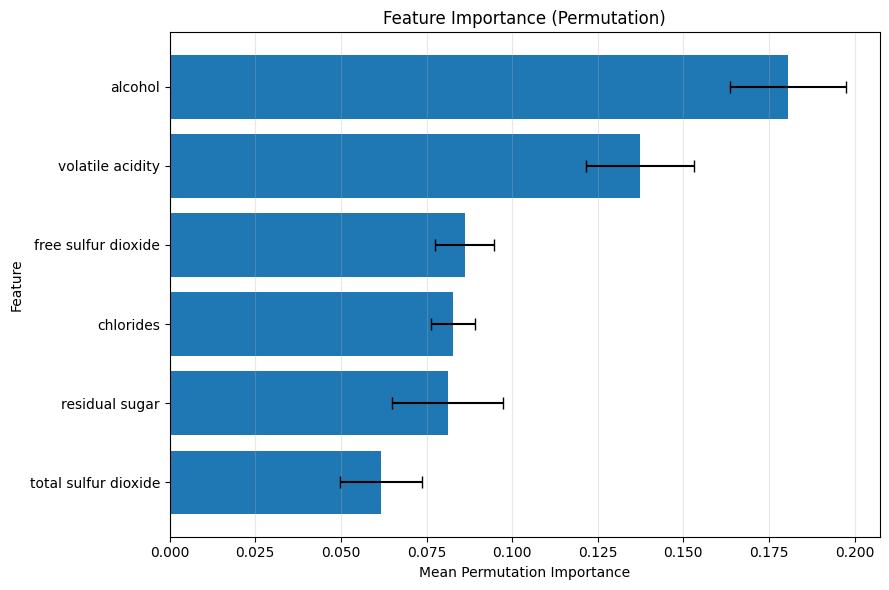

In [25]:
plot_feature_importance(ftre_importance_df_rf)

In [26]:
cm_rfreg = confusion_matrix(y_test, np.round(np.clip(y_pred_rf, 1, 9)))

labels = ['3','4','5','6','7','8','9']

cm_df = pd.DataFrame(
    cm_rfreg,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Pred: {label}" for label in labels],
)

print(cm_df)

           Pred: 3  Pred: 4  Pred: 5  Pred: 6  Pred: 7  Pred: 8  Pred: 9
Actual: 3        0        0        1        3        1        0        0
Actual: 4        0        7       13        9        0        0        0
Actual: 5        0        4      137       66        3        0        0
Actual: 6        0        0       50      251       39        0        0
Actual: 7        0        0        3       55       62        2        0
Actual: 8        0        0        1       10        9        8        0
Actual: 9        0        0        0        1        0        0        0


In [28]:
labels = ['3','4','5','6','7','8','9']
scores = precision_score(y_test, np.round(np.clip(y_pred_rf, 1, 10)).astype(int), labels=labels, average=None, zero_division=0)

# Pair each class name with its precision score
class_precision = dict(zip(labels, scores))
print(class_precision)

{'3': np.float64(0.0), '4': np.float64(0.6363636363636364), '5': np.float64(0.6682926829268293), '6': np.float64(0.6354430379746835), '7': np.float64(0.543859649122807), '8': np.float64(0.8), '9': np.float64(0.0)}


## 14. Dummy-model benchmarks

A mean-prediction `DummyRegressor` and a most-frequent-class `DummyClassifier` provide simple reference baselines. Both are fitted on the training subset and evaluated on the test subset.

As before, we use advanced feature selection below:

Let us benchmark our results by defining a dummy classifier and regressor as follows

In [31]:
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train, y_train)

dummy_clf = DummyClassifier(strategy = 'most_frequent').fit(X_train, y_train)

y_pred_dummy_clf = dummy_clf.predict(X_test)
y_pred_dummy_reg = dummy_reg.predict(X_test)

print("accuracy with T=0.5 for dummy regression: ", round(accuracy_t(y_test, y_pred_dummy_reg),2))
print("accuracy for dummy classification: ", round(accuracy_score(y_test, y_pred_dummy_clf),2))

accuracy with T=0.5 for dummy regression:  0.46
accuracy for dummy classification:  0.46
